# Comparing classifiers fairly: Iris with scikit-learn pipelines

**Module 03.1 · my implementation**, Seid Adem

The course introduces machine learning with the **Iris** dataset. This notebook re-implements that workflow the way it
should be done in a real project:

* every model is a **`Pipeline`**, so preprocessing is learned from training data only;
* models are compared with **repeated, stratified cross-validation** and a **baseline**, not one lucky split;
* the **test set is used once**, at the end, and its uncertainty is reported;
* a second dataset shows **why scaling matters** for some models and not others.

> **New to machine learning?** Read [Lesson 5 (overfitting and splits)](../LESSONS.md#lesson-5--overfitting-underfitting-and-the-traintest-split)
> and [Lesson 6 (the algorithm families)](../LESSONS.md#lesson-6--a-tour-of-the-algorithm-families) first. Each section
> below starts with a plain-language box like this one.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import binomtest
from sklearn.datasets import load_iris, load_wine
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import (
    RepeatedStratifiedKFold,
    StratifiedKFold,
    cross_val_predict,
    cross_val_score,
    cross_validate,
    train_test_split,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
SEED = 0

## 1 · The data, and a split we will not touch until the end

> **In plain language.** Iris has 150 flowers from three species. For each flower, four lengths are measured in
> centimetres: sepal length and width, and petal length and width. (Sepals are the leaf-like parts under the petals.)
> The task is to **predict the species from the four measurements**. We hide a quarter of the flowers in a
> **test set**, which plays the role of "new flowers the model has never seen".

`stratify=y` keeps the three species in equal proportions in both parts.

In [2]:
iris = load_iris(as_frame=True)
X, y = iris.data, iris.target.map(dict(enumerate(map(str, iris.target_names))))
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)

print(f"{len(X_train)} training flowers, {len(X_test)} test flowers")
print(y_train.value_counts().to_dict())
X.describe().T[["mean", "std", "min", "max"]].round(2)

112 training flowers, 38 test flowers
{'setosa': 38, 'virginica': 37, 'versicolor': 37}


,mean,std,min,max
sepal length (cm),5.84,0.83,4.3,7.9
sepal width (cm),3.06,0.44,2.0,4.4
petal length (cm),3.76,1.77,1.0,6.9
petal width (cm),1.20,0.76,0.1,2.5


All four features are in centimetres and have similar spreads (standard deviation 0.4–1.8 cm). Keep that in mind for
section 4.

## 2 · Four models, one protocol

> **In plain language.** We compare three real models with a **baseline** that always guesses the most common species.
> A model is only useful if it clearly beats this "no-skill" guess. Instead of one train/validation split, we use
> **cross-validation**: cut the training data into 5 parts, train on 4, score on the 5th, rotate, and then repeat the
> whole thing 10 times with different cuts. That gives **50 scores per model**, so we can see how much results vary
> by chance.

| Model | Intuition | Needs scaling? |
|-------|-----------|----------------|
| Most-frequent baseline | always predicts the majority class | no |
| Logistic regression | a weighted sum of features turned into class probabilities; straight boundaries | yes (the penalty treats all weights alike) |
| SVM (RBF kernel) | the widest-margin boundary, allowed to curve | **yes** (it measures distances) |
| Random forest | many decision trees vote | no (trees only compare a feature with a threshold) |

The scaler is *inside* each pipeline, so in every fold it is fitted on the four training parts only.

In [3]:
models = {
    "Baseline (most frequent)": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "SVM (RBF)": make_pipeline(StandardScaler(), SVC()),
    "Random forest": RandomForestClassifier(random_state=SEED),
}
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEED)

results = {
    name: cross_validate(
        model, X_train, y_train, cv=cv, scoring=["accuracy", "f1_macro"], return_train_score=True
    )
    for name, model in models.items()
}
summary = pd.DataFrame(
    {
        name: {
            "CV accuracy (mean)": r["test_accuracy"].mean(),
            "CV accuracy (SD)": r["test_accuracy"].std(),
            "CV macro-F1": r["test_f1_macro"].mean(),
            "training accuracy": r["train_accuracy"].mean(),
        }
        for name, r in results.items()
    }
).T.round(3)
summary

,CV accuracy (mean),CV accuracy (SD),CV macro-F1,training accuracy
Baseline (most frequent),0.339,0.018,0.169,0.339
Logistic regression,0.966,0.032,0.966,0.971
SVM (RBF),0.961,0.035,0.960,0.969
Random forest,0.954,0.037,0.953,1.000


**Reading the table**

* All three models beat the baseline by a wide margin (about 0.96 vs 0.34).
* **The random forest scores 1.000 on its own training data** but about 0.95 in cross-validation. It memorises the
  training flowers, yet still generalises. A perfect training score on its own tells you nothing; only held-out
  scores count.
* **The differences between the three models are smaller than the spread across folds.** The next cell checks this
  directly.

In [4]:
acc = {name: r["test_accuracy"] for name, r in results.items()}
for a, b in [("Logistic regression", "SVM (RBF)"), ("Logistic regression", "Random forest")]:
    diff = acc[a] - acc[b]  # same folds for both models, so the difference is paired
    print(
        f"{a} − {b}: mean {diff.mean():+.3f}, SD {diff.std():.3f}; "
        f"{a} better on {(diff > 0).mean():.0%} of folds, tied on {(diff == 0).mean():.0%}"
    )

Logistic regression − SVM (RBF): mean +0.005, SD 0.017; Logistic regression better on 10% of folds, tied on 90%
Logistic regression − Random forest: mean +0.012, SD 0.025; Logistic regression better on 26% of folds, tied on 72%


> **In plain language.** On most folds the models make *exactly the same number of mistakes*. The average gap
> (about 1 percentage point) is far smaller than the fold-to-fold variation (about 3 points). The honest conclusion is
> **"these three models perform equivalently on Iris"**, not "logistic regression wins".

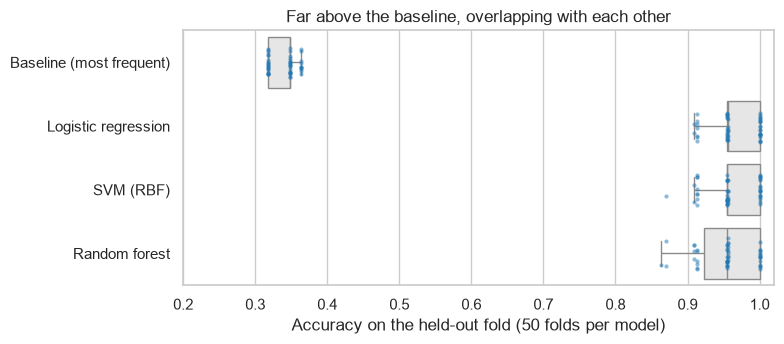

In [5]:
long = pd.concat(
    [pd.DataFrame({"model": name, "accuracy": r["test_accuracy"]}) for name, r in results.items()],
    ignore_index=True,
)
fig, ax = plt.subplots(figsize=(8, 3.6))
sns.boxplot(data=long, y="model", x="accuracy", color="0.9", showfliers=False, ax=ax)
sns.stripplot(data=long, y="model", x="accuracy", size=3, alpha=0.5, jitter=0.25, color="tab:blue", ax=ax)
ax.set(xlabel="Accuracy on the held-out fold (50 folds per model)", ylabel="", xlim=(0.2, 1.02))
ax.set_title("Far above the baseline, overlapping with each other")
fig.tight_layout()
fig.savefig(FIGURES / "01_cv_scores.png", dpi=150)
plt.show()

## 3 · Which flowers get confused?

> **In plain language.** A **confusion matrix** counts, for each true species (rows), which species the model
> predicted (columns). The diagonal holds the correct predictions. Here each training flower is predicted by a model
> that did not see it (`cross_val_predict`).

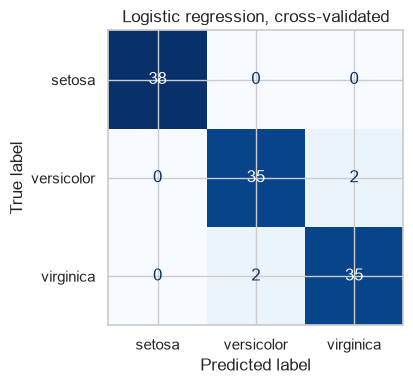

In [6]:
pred = cross_val_predict(
    models["Logistic regression"], X_train, y_train, cv=StratifiedKFold(5, shuffle=True, random_state=SEED)
)
fig, ax = plt.subplots(figsize=(4.6, 4))
ConfusionMatrixDisplay.from_predictions(y_train, pred, ax=ax, colorbar=False, cmap="Blues")
ax.set_title("Logistic regression, cross-validated")
fig.tight_layout()
fig.savefig(FIGURES / "02_confusion_matrix.png", dpi=150)
plt.show()

*Setosa* is never confused. Every error is between *versicolor* and *virginica*. The next figure shows why: with the
two petal measurements, setosa forms a separate island, while the other two species overlap at their border.
For display only, each model is refitted on these **two** features (a 2-D picture needs two inputs).

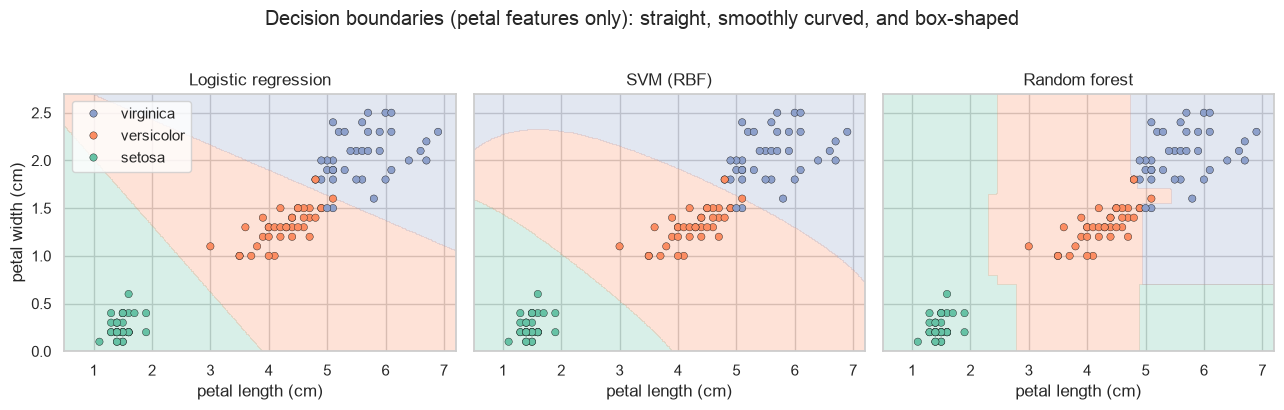

In [7]:
petal = ["petal length (cm)", "petal width (cm)"]
xx, yy = np.meshgrid(np.linspace(0.5, 7.2, 300), np.linspace(0, 2.7, 300))
grid = pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=petal)
species = [str(s) for s in iris.target_names]
palette = dict(zip(species, sns.color_palette("Set2", 3), strict=True))

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, name in zip(axes, ["Logistic regression", "SVM (RBF)", "Random forest"], strict=True):
    m = models[name].fit(X_train[petal], y_train)
    z = pd.Series(m.predict(grid)).map(species.index).to_numpy().reshape(xx.shape)
    ax.contourf(xx, yy, z, levels=[-0.5, 0.5, 1.5, 2.5], colors=[palette[s] for s in species], alpha=0.25)
    sns.scatterplot(
        data=X_train.assign(species=y_train),
        x=petal[0],
        y=petal[1],
        hue="species",
        palette=palette,
        edgecolor="k",
        linewidth=0.3,
        s=28,
        ax=ax,
        legend=ax is axes[0],
    )
    ax.set_title(name)
axes[0].legend(title="", loc="upper left")
fig.suptitle("Decision boundaries (petal features only): straight, smoothly curved, and box-shaped", y=1.02)
fig.tight_layout()
fig.savefig(FIGURES / "03_decision_boundaries.png", dpi=150, bbox_inches="tight")
plt.show()

> **In plain language.** Each colour region is "where the model would say this species". **Logistic regression**
> draws straight lines, the **SVM** draws smooth curves, and the **random forest** draws axis-aligned steps, because
> each tree asks questions like "is petal width > 1.7 cm?". All three agree wherever the data is; they disagree only
> in empty space and in the narrow versicolor/virginica border. That is why their scores are so similar.
>
> Look at the bottom-right corner of the random-forest panel: it predicts *setosa* for long, thin petals, where no
> flower exists. Every model has to say *something* in empty regions, and those answers are arbitrary. **A model is
> only trustworthy close to the data it was trained on.** In biology this matters when a model meets a new cell
> type, a new instrument or a new patient population.

## 4 · Why scaling matters (sometimes): the Wine dataset

> **In plain language.** Models that measure **distances** (SVM, k-nearest neighbours) treat a difference of 1 unit
> the same in every feature. If one feature is measured in hundreds and another in fractions, the big one dominates
> and the small ones are ignored. **Standardising** (subtract the mean, divide by the standard deviation) puts all
> features on the same footing. Trees don't care, because they only compare each feature with its own threshold.

Iris can't show this, because its features share a unit and a range. The **Wine** dataset (178 wines, 13 chemical
measurements, 3 grape cultivars) can: its features range from about 0.1 to about 1,700.

In [8]:
X_wine, y_wine = load_wine(return_X_y=True, as_frame=True)
spread = X_wine.std().sort_values()
print(
    f"smallest SD: {spread.index[0]} = {spread.iloc[0]:.2f};  largest SD: {spread.index[-1]} = {spread.iloc[-1]:.0f}"
)

pairs = {
    "SVM (RBF)": (SVC(), make_pipeline(StandardScaler(), SVC())),
    "k-nearest neighbours": (KNeighborsClassifier(), make_pipeline(StandardScaler(), KNeighborsClassifier())),
    "Random forest": (
        RandomForestClassifier(random_state=SEED),
        make_pipeline(StandardScaler(), RandomForestClassifier(random_state=SEED)),
    ),
}
rows = []
for name, (raw, scaled) in pairs.items():
    for label, model in [("raw features", raw), ("standardised in pipeline", scaled)]:
        s = cross_val_score(model, X_wine, y_wine, cv=cv)
        rows.append({"model": name, "input": label, "accuracy": s.mean(), "SD": s.std()})
wine = pd.DataFrame(rows)
wine.pivot(index="model", columns="input", values="accuracy").round(3)

smallest SD: nonflavanoid_phenols = 0.12;  largest SD: proline = 315


input,raw features,standardised in pipeline
model,,
Random forest,0.980,0.980
SVM (RBF),0.683,0.981
k-nearest neighbours,0.706,0.962


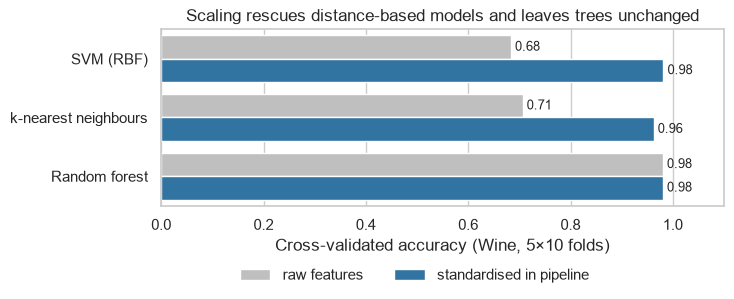

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
sns.barplot(data=wine, y="model", x="accuracy", hue="input", palette=["0.75", "tab:blue"], ax=ax)
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", padding=3, fontsize=9)
ax.set(xlim=(0, 1.1), xlabel="Cross-validated accuracy (Wine, 5×10 folds)", ylabel="")
ax.legend(title="", loc="upper center", bbox_to_anchor=(0.45, -0.28), ncol=2, frameon=False)
ax.set_title("Scaling rescues distance-based models and leaves trees unchanged")
fig.tight_layout()
fig.savefig(FIGURES / "04_scaling_effect.png", dpi=150, bbox_inches="tight")
plt.show()

Without scaling, the SVM and KNN are dominated by `proline` (SD about 315) and lose 25–30 accuracy points. The
random forest gives the same score either way. **Rule of thumb:** always put the scaler in the pipeline. It costs
nothing for trees and is essential for distance- and margin-based models.

## 5 · The test set, used once

> **In plain language.** Now we fit each model on all training flowers and score it on the 38 hidden test flowers,
> once. With only 38 flowers, **each flower is worth 2.6 percentage points**, so we also report a 95 % confidence
> interval: the range of true accuracies consistent with what we observed.

In [10]:
rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    correct = int((model.predict(X_test) == y_test).sum())
    ci = binomtest(correct, len(y_test)).proportion_ci(method="wilson")
    rows.append(
        {
            "model": name,
            "correct": f"{correct}/{len(y_test)}",
            "test accuracy": correct / len(y_test),
            "95% CI": f"{ci.low:.2f}–{ci.high:.2f}",
            "CV accuracy": summary.loc[name, "CV accuracy (mean)"],
        }
    )
pd.DataFrame(rows).set_index("model").round(3)

,correct,test accuracy,95% CI,CV accuracy
model,,,,
Baseline (most frequent),12/38,0.316,0.19–0.47,0.339
Logistic regression,35/38,0.921,0.79–0.97,0.966
SVM (RBF),36/38,0.947,0.83–0.99,0.961
Random forest,34/38,0.895,0.76–0.96,0.954


**The ranking flips.** In cross-validation the order was logistic regression > SVM > random forest; on the test set it
is SVM > logistic regression > random forest. The gaps are one or two flowers, and the confidence intervals overlap
almost completely. This is the most useful lesson in the notebook:

> **A single small test set can't rank models that are this close.** Use cross-validation to compare and choose, use
> the test set to confirm the chosen model works on new data, and report the uncertainty either way.

For completeness, the per-class report of the cross-validated predictions from section 3:

In [11]:
print(classification_report(y_train, pred, digits=3))

              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        38
  versicolor      0.946     0.946     0.946        37
   virginica      0.946     0.946     0.946        37

    accuracy                          0.964       112
   macro avg      0.964     0.964     0.964       112
weighted avg      0.964     0.964     0.964       112



## Conclusions

1. **All three models are equivalent on Iris** (CV accuracy 0.95–0.97, gaps smaller than the fold-to-fold spread),
   and all are far above the 0.34 baseline.
2. **The only hard part of the problem is the versicolor/virginica border.** Setosa is perfectly separable.
3. **Scaling must live inside the pipeline.** On Wine it moves SVM and KNN from about 0.7 to above 0.96 and leaves
   the random forest unchanged.
4. **A 38-sample test set reorders near-identical models.** Rank with repeated CV, confirm once on the test set, and
   always report uncertainty.

**If this were a real project** I would choose logistic regression: equal performance, the simplest model, fast,
and its coefficients can be read directly.

---
*Data: Iris (Fisher, 1936) and Wine (UCI) datasets, bundled with scikit-learn. Runs offline in under a minute.*